# [12.6] Multimodal SAEs, Transcoders and Crosscoders (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part6_multimodal_sparse_features/12.6_Multimodal_SAEs_Transcoders_and_Crosscoders_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part6_multimodal_sparse_features/12.6_Multimodal_SAEs_Transcoders_and_Crosscoders_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

A red square and the words **red square** should share something, but the image is also bright and the words also have a length. If one latent responds to both, have we found a shared concept or merely paired two nuisance variables?

By the end of this notebook, you will have linked rendered objects, their words and an answer path in a specified sparse-feature organism, using matched versus shuffled activation matrices and a feature-to-answer circuit with ablation controls. Every encoding, objective, edge calculation and intervention is visible and student implemented.

This is a small **known-dictionary CPU organism**, not features extracted from a pretrained VLM. We fit tiny decoders to inspect the objectives; the encoder dictionaries are declared, so we do not call their semantic labels an unsupervised discovery. The deliberate nuisance channels show why reconstruction, cross-modal alignment and downstream use need separate tests. Prerequisites: [6.1] SAEs, [6.4] transcoders, [6.5] crosscoders and [12.3] the vision-projector-language decomposition. If those are new, complete parts1–2 first.

## Content & Learning Objectives

### 1️⃣ Pair an image with its name

> ##### Learning Objectives
>
> - Build matched pixel and word features while keeping brightness and word length separate.

### 2️⃣ Three sparse questions, three targets

> ##### Learning Objectives
>
> - Implement SAE reconstruction, transcoder prediction and decoder fitting without conflating their objectives.

### 3️⃣ Which features really cross modalities?

> ##### Learning Objectives
>
> - Implement joint encoding, paired reconstruction and image/text support-overlap controls.

### 4️⃣ From a shared feature to an answer path

> ##### Learning Objectives
>
> - Compute sparse-feature edges, contrast contributions and residual-preserving interventions.

## Setup code

This study edition uses NumPy, Matplotlib and Pillow already installed in the course environment. All arrays are CPU float64, all examples are deterministic, and no model or network access occurs.

In [ ]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapter12_vlm_interpretability").exists())
exercises_dir = root_dir / "chapter12_vlm_interpretability" / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
from part6_multimodal_sparse_features import tests as tests
from part6_multimodal_sparse_features import utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=3, suppress=True)

# 1️⃣ Pair an image with its name

> ##### Learning Objectives
>
> - Build matched pixel and word features while keeping brightness and word length separate.

The six examples are three coloured shapes at two brightness levels, paired with their exact names. Our visual feature array `(example,4)` contains a one-hot dominant mean-RGB channel and global brightness. Its text counterpart contains a one-hot vocabulary entry and string length divided by10. These are declared features, not an OCR system or language embedding. Colour and object identity are confounded; that confines our claim to this world.

A VLM offers several distinct activation sites: vision-encoder output, projector output, and language-model residuals at image and text positions. Equal widths do not make those sites equivalent. Our two four-coordinate sites make the distinction visible before introducing a joint code.

### Exercise - implement `pixel_statistics`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(batch,4)`: one-hot dominant mean RGB and the mean of all RGB pixels. A black image has a deterministic first-index colour tie; document it rather than treating it as visual evidence.

In [ ]:
def pixel_statistics(images):
    raise NotImplementedError()


tests.test_pixel_statistics(pixel_statistics)

<details>
<summary>Hint</summary>

The brightness channel must preserve intensity; normalising it would remove the nuisance we want to measure.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_pixel_statistics passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def pixel_statistics(images):
    means = images.mean(axis=(1,2))
    colour = np.eye(3)[means.argmax(axis=1)]
    brightness = images.mean(axis=(1,2,3))[:,None]
    return np.concatenate([colour,brightness],axis=1)
```
</details>

### Exercise - implement `word_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Map each full string to its exact vocabulary index and append `len(word)/10`. Return an array with `(len(words),len(vocabulary)+1)` shape; unknown strings raise `ValueError`. Tokenisation is intentionally transparent here.

In [ ]:
def word_features(words, vocabulary):
    raise NotImplementedError()


tests.test_word_features(word_features)

<details>
<summary>Hint</summary>

Do not pair by sorting names: image/text row identity must remain exact.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_word_features passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def word_features(words, vocabulary):
    indices = [vocabulary.index(word) for word in words]
    return np.concatenate([np.eye(len(vocabulary))[indices],np.array([len(word)/10 for word in words])[:,None]],axis=1)
```
</details>


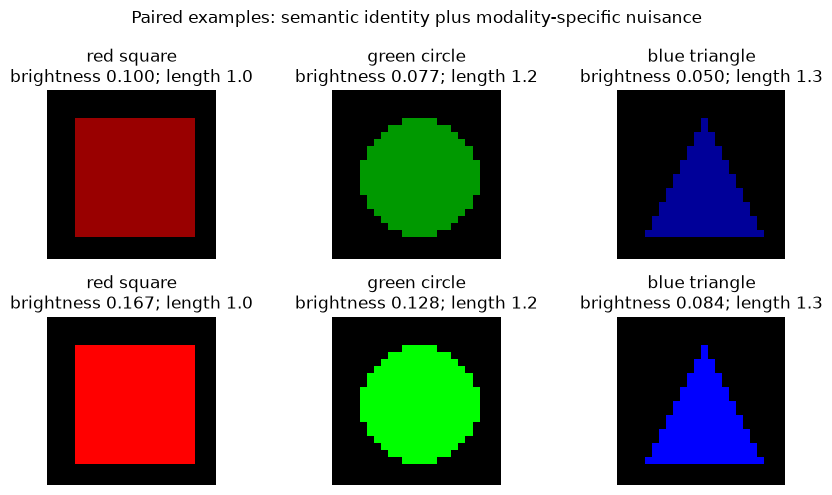

In [ ]:
images, labels, words = utils.render_examples()
visual = pixel_statistics(images)
text = word_features(words,list(utils.NAMES))
fig,axes=plt.subplots(2,3,figsize=(9,5))
for i,ax in enumerate(axes.flat):
    ax.imshow(images[i]);ax.set_title(f"{words[i]}\nbrightness {visual[i,-1]:.3f}; length {text[i,-1]:.1f}");ax.axis("off")
fig.suptitle("Paired examples: semantic identity plus modality-specific nuisance")
plt.tight_layout();plt.show()

<details><summary>Help - why retain nuisance channels?</summary>

A decoder can reconstruct a paired dataset partly by exploiting correlations. Two brightness levels keep one nuisance variable from being a perfect proxy for class. Word length still correlates with identity; that is an honest limitation to challenge later. A high reconstruction score alone cannot tell us that the code uses the intended shared concept.

</details>

## Summary of 1️⃣

A paired row is the unit of alignment. We know the source of each channel and can construct controls without changing the semantic vocabulary.

# 2️⃣ Three sparse questions, three targets

> ##### Learning Objectives
>
> - Implement SAE reconstruction, transcoder prediction and decoder fitting without conflating their objectives.

An **SAE** encodes $x$ and reconstructs the same activation site: $z=\operatorname{ReLU}(xW_e+b_e)$, $\hat x=zD+b_d$. A **transcoder** instead predicts a target computation, for example an MLP output $y=f(x)$, from a sparse code of its input. A **crosscoder** reads and writes multiple sites with a shared code. These distinctions are about inputs and targets, not just tensor shapes.

Here, squared error means the sum over feature coordinates averaged over examples. The decoder fit below uses an intercept and an optional ridge penalty on decoder weights **only**. It is a small least-squares fit on monitored examples, not a training recipe for a full sparse model. A real SAE/transcoder must also learn or select its encoder with reconstruction/sparsity and downstream-replacement checks.

### Exercise - implement `sae_encode`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement affine ReLU encoding for arbitrary input and latent widths. Bias is latent-shaped, not example-shaped.

In [ ]:
def sae_encode(x, encoder, bias):
    raise NotImplementedError()


tests.test_sae_encode(sae_encode)

<details>
<summary>Hint</summary>

The sparse latent is the post-nonlinearity value, not the signed preactivation.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_sae_encode passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def sae_encode(x, encoder, bias):
    return np.maximum(x @ encoder + bias,0)
```
</details>

### Exercise - implement `reconstruct`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Decode latent rows through a row-per-feature dictionary and add the output-site bias. The output width need not equal the input width.

In [ ]:
def reconstruct(z, decoder, bias):
    raise NotImplementedError()


tests.test_reconstruct(reconstruct)

<details>
<summary>Hint</summary>

An SAE and a transcoder may share this operation while having different reconstruction targets.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_reconstruct passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def reconstruct(z, decoder, bias):
    return z @ decoder + bias
```
</details>

### Exercise - implement `reconstruction_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return mean per-example sum of squared coordinate errors. Preserve the distinction between coordinate sum and coordinate mean.

In [ ]:
def reconstruction_error(target, prediction):
    raise NotImplementedError()


tests.test_reconstruction_error(reconstruction_error)

<details>
<summary>Hint</summary>

One example with twice as many equally wrong coordinates should have twice the error.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_reconstruction_error passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def reconstruction_error(target, prediction):
    return float(np.mean(np.sum((target-prediction)**2,axis=1)))
```
</details>

### Exercise - implement `transcoder_targets`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute the declared target MLP: `relu(x @ weights + bias)`. This is the function whose output the sparse transcoder must predict; it is not the SAE target `x`.

In [ ]:
def transcoder_targets(x, weights, bias):
    raise NotImplementedError()


tests.test_transcoder_targets(transcoder_targets)

<details>
<summary>Hint</summary>

Changing the target from the input to an MLP output changes what a good code must preserve.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_transcoder_targets passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def transcoder_targets(x, weights, bias):
    return np.maximum(x @ weights + bias,0)
```
</details>

### Exercise - implement `fit_decoder`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Fit a decoder and intercept using centred least squares. For `ridge>0`, solve the regularised normal equations for the centred variables; for zero ridge use `np.linalg.lstsq`. Return `(decoder,intercept)`. Penalise no intercept.

In [ ]:
def fit_decoder(z, targets, ridge=1e-6):
    raise NotImplementedError()


tests.test_fit_decoder(fit_decoder)

<details>
<summary>Hint</summary>

Centre both sides. The fitted intercept restores the means and must not shrink under ridge.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_fit_decoder passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def fit_decoder(z, targets, ridge=1e-6):
    zc = z-z.mean(axis=0)
    yc = targets-targets.mean(axis=0)
    if ridge < 0:
        raise ValueError("Ridge must be nonnegative")
    if ridge == 0:
        decoder = np.linalg.lstsq(zc,yc,rcond=None)[0]
    else:
        decoder = np.linalg.solve(zc.T @ zc + ridge*np.eye(z.shape[1]),zc.T @ yc)
    intercept = targets.mean(axis=0)-z.mean(axis=0) @ decoder
    return decoder,intercept
```
</details>


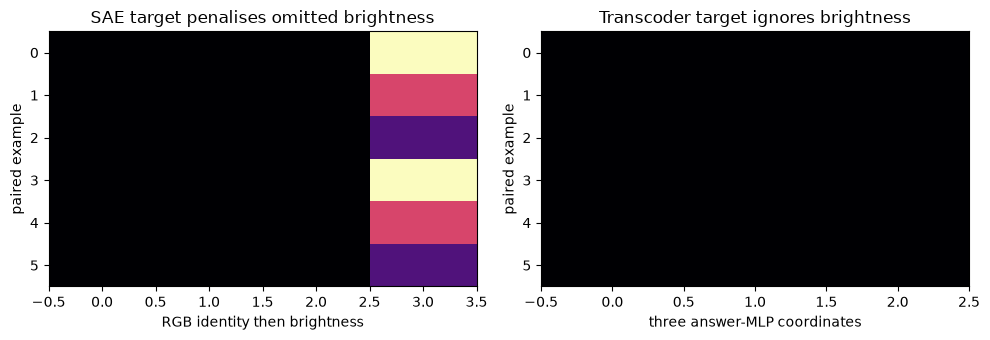

In [ ]:
# A semantic-only sparse code deliberately omits brightness.
semantic_code = visual[:,:3]
mlp_weights = np.array([[1.,0,0],[0,1,0],[0,0,1],[0,0,0]])
mlp_bias = np.zeros(3)
mlp_target = transcoder_targets(visual,mlp_weights,mlp_bias)
sae_decoder,sae_bias = fit_decoder(semantic_code,visual)
trans_decoder,trans_bias = fit_decoder(semantic_code,mlp_target)
sae_errors = (reconstruct(semantic_code,sae_decoder,sae_bias)-visual)**2
trans_errors = (reconstruct(semantic_code,trans_decoder,trans_bias)-mlp_target)**2
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].imshow(sae_errors,aspect="auto",cmap="magma");axes[0].set(xlabel="RGB identity then brightness",ylabel="paired example",title="SAE target penalises omitted brightness")
axes[1].imshow(trans_errors,aspect="auto",cmap="magma",vmin=0,vmax=max(float(sae_errors.max()),1e-6));axes[1].set(xlabel="three answer-MLP coordinates",ylabel="paired example",title="Transcoder target ignores brightness")
plt.tight_layout();plt.show()
print("SAE target error",round(reconstruction_error(visual,reconstruct(semantic_code,sae_decoder,sae_bias)),6))
print("transcoder target error",round(reconstruction_error(mlp_target,reconstruct(semantic_code,trans_decoder,trans_bias)),6))

<details><summary>Help - same code, different verdict</summary>

The semantic-only code cannot reconstruct both brightness values for one object, so the SAE error remains positive. Our answer MLP explicitly ignores brightness; the same code predicts that target nearly exactly. This is an objective comparison on a known computation, not evidence that a learned real transcoder is automatically more faithful. Inspect the omitted error channel before interpreting a scalar average.

</details>

## Summary of 2️⃣

Choose the reconstruction target before judging a code. A low-error replacement of the actual downstream computation is a separate claim from input reconstruction.

# 3️⃣ Which features really cross modalities?

> ##### Learning Objectives
>
> - Implement joint encoding, paired reconstruction and image/text support-overlap controls.

Our five code coordinates are red-object, green-object, blue-object, image brightness and text length. The joint encoder adds two site-specific affine contributions **before** ReLU:

$$z=\operatorname{ReLU}(xW_x+yW_y+b).$$

We weight each site’s semantic contribution by1/2, so a paired example has full semantic activation. Encoding either site alone gives half activation with the same support. The nuisance dimensions belong to one site each. This known dictionary is a ground-truth reference for testing crosscoder mechanics; discovering such a dictionary in a real VLM is a further task.

### Exercise - implement `crosscoder_encode`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement additive two-site encoding followed by one ReLU. `w_x` and `w_y` may have different input widths but must share a latent width. Do not concatenate independent post-ReLU codes.

In [ ]:
def crosscoder_encode(x, y, w_x, w_y, bias):
    raise NotImplementedError()


tests.test_crosscoder_encode(crosscoder_encode)

<details>
<summary>Hint</summary>

Nonlinearity placement matters when one site contributes positive and the other negative evidence.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_crosscoder_encode passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def crosscoder_encode(x, y, w_x, w_y, bias):
    return np.maximum(x @ w_x + y @ w_y + bias,0)
```
</details>

### Exercise - implement `crosscoder_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Sum the two mean per-example squared reconstruction errors and add `alpha * mean(sum(z,axis=1))`. The single sparse code is penalised once, not once per reconstructed modality.

In [ ]:
def crosscoder_loss(x, y, x_hat, y_hat, z, alpha):
    raise NotImplementedError()


tests.test_crosscoder_loss(crosscoder_loss)

<details>
<summary>Hint</summary>

Keep site widths from silently changing the penalty through a global coordinate average.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_crosscoder_loss passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def crosscoder_loss(x, y, x_hat, y_hat, z, alpha):
    return reconstruction_error(x,x_hat)+reconstruction_error(y,y_hat)+alpha*float(z.sum(axis=1).mean())
```
</details>

### Exercise - implement `feature_overlap`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

For each latent, return the Jaccard overlap between its above-threshold image-only and text-only support sets over paired examples. A latent inactive in both sites gets overlap0, not1.

In [ ]:
def feature_overlap(image_z, text_z, threshold=0.1):
    raise NotImplementedError()


tests.test_feature_overlap(feature_overlap)

<details>
<summary>Hint</summary>

Support overlap measures which examples activate a latent, not whether the numeric magnitudes match.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_feature_overlap passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def feature_overlap(image_z, text_z, threshold=0.1):
    left = image_z > threshold
    right = text_z > threshold
    intersection = (left & right).sum(axis=0)
    union = (left | right).sum(axis=0)
    return intersection / np.maximum(union,1)
```
</details>

### Exercise - implement `derange_pairs`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a one-row cyclic shift of the text activation array, requiring at least two rows. Every paired row must change, and the original array must stay intact. This control preserves marginal activations while breaking the declared image/text pairing.

In [ ]:
def derange_pairs(x):
    raise NotImplementedError()


tests.test_derange_pairs(derange_pairs)

<details>
<summary>Hint</summary>

A cyclic shift has no fixed row positions; equal semantic labels may still repeat, so inspect labels as well.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_derange_pairs passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def derange_pairs(x):
    if len(x) < 2:
        raise ValueError("Need at least two paired examples")
    return np.roll(x,1,axis=0).copy()
```
</details>


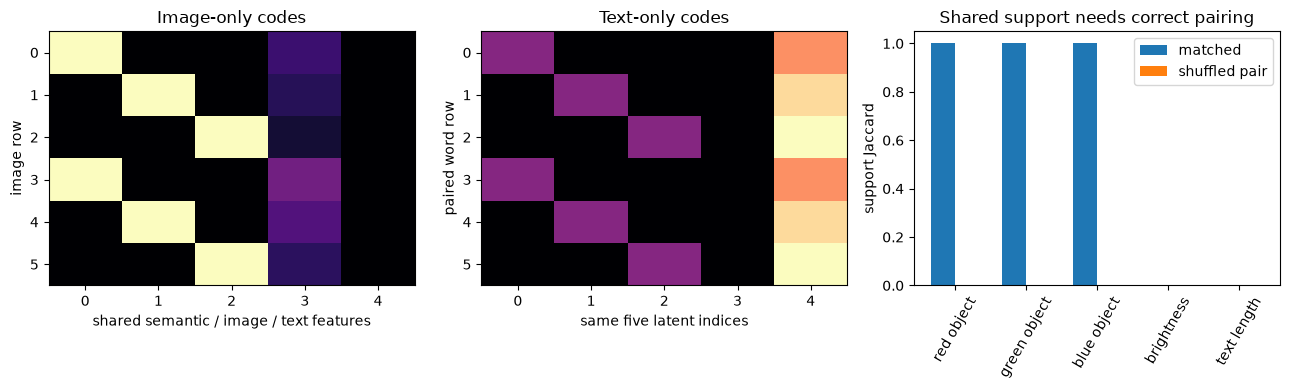

In [ ]:
w_x = np.zeros((4,5));w_y = np.zeros((4,5))
w_x[:3,:3] = .5*np.eye(3);w_y[:3,:3] = .5*np.eye(3)
w_x[3,3] = 1;w_y[3,4] = 1
z = crosscoder_encode(visual,text,w_x,w_y,np.zeros(5))
image_z = crosscoder_encode(visual,np.zeros_like(text),w_x,w_y,np.zeros(5))
text_z = crosscoder_encode(np.zeros_like(visual),text,w_x,w_y,np.zeros(5))
d_x = np.zeros((5,4));d_y = np.zeros((5,4))
d_x[:3,:3] = np.eye(3);d_y[:3,:3] = np.eye(3);d_x[3,3]=1;d_y[4,3]=1
objective = crosscoder_loss(visual,text,reconstruct(z,d_x,np.zeros(4)),reconstruct(z,d_y,np.zeros(4)),z,.01)
print("known crosscoder objective",round(objective,6))
feature_names=["red object","green object","blue object","brightness","text length"]
fig,axes=plt.subplots(1,3,figsize=(13,4))
axes[0].imshow(image_z,aspect="auto",cmap="magma");axes[0].set(xlabel="shared semantic / image / text features",ylabel="image row",title="Image-only codes")
axes[1].imshow(text_z,aspect="auto",cmap="magma");axes[1].set(xlabel="same five latent indices",ylabel="paired word row",title="Text-only codes")
idx=np.arange(5)
axes[2].bar(idx-.17,feature_overlap(image_z,text_z),.34,label="matched");axes[2].bar(idx+.17,feature_overlap(image_z,derange_pairs(text_z)),.34,label="shuffled pair");axes[2].set(xticks=idx,xticklabels=feature_names,ylabel="support Jaccard",title="Shared support needs correct pairing");axes[2].tick_params(axis="x",labelrotation=60);axes[2].legend()
plt.tight_layout();plt.show()

<details><summary>Help - what the shuffled control preserves</summary>

The first three features share support across the correctly paired image and text rows. Their shuffled-pair support fails even though each modality’s activation histogram is unchanged. Brightness and text length are not shared features: each is absent from the other modality. Because the encoder dictionaries are specified, this checks the definition and control rather than demonstrating feature discovery.

</details>

## Summary of 3️⃣

A crosscoder shares a code across sites. Paired support, reconstruction and modality-specific nuisance are different parts of its interpretation.

# 4️⃣ From a shared feature to an answer path

> ##### Learning Objectives
>
> - Compute sparse-feature edges, contrast contributions and residual-preserving interventions.

For a linear map between two sparse encodings, a source feature’s decoder row $d_i$ reaches downstream feature $j$ with weight $d_iW_{e,j}$. An answer contrast with readout coefficient $u_j$ receives a local contribution $z_i(d_iW_{e,j})u_j$. These products are exact only for the declared linear route (or a fixed local activation regime); a nonlinear real circuit needs reconstruction-error terms, gating checks and intervention validation.

Our answer computation reads the three semantic coordinates and ignores brightness. The text-length latent has no image decoder contribution. We will retain the reconstruction residual during ablation rather than replacing the entire activation by a possibly imperfect sparse reconstruction.

### Exercise - implement `feature_edges`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the source-latent by downstream-latent matrix obtained by multiplying source decoder rows `(source,input_width)` by downstream encoder `(input_width,target)`. Preserve signs.

In [ ]:
def feature_edges(source_decoder, downstream_encoder):
    raise NotImplementedError()


tests.test_feature_edges(feature_edges)

<details>
<summary>Hint</summary>

The shared activation width is the contracted axis; latent indices label the output axes.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_feature_edges passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def feature_edges(source_decoder, downstream_encoder):
    return source_decoder @ downstream_encoder
```
</details>

### Exercise - implement `path_contribution`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(batch,source,target)` contributions from source activations, an edge matrix and a downstream answer-contrast readout vector. Sum over source and target to recover the declared linear contrast.

In [ ]:
def path_contribution(z, edges, contrast_readout):
    raise NotImplementedError()


tests.test_path_contribution(path_contribution)

<details>
<summary>Hint</summary>

Keep the source and target axes until the final diagnostic; summing too early hides cancellation.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_path_contribution passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def path_contribution(z, edges, contrast_readout):
    return z[:,:,None] * edges[None,:,:] * contrast_readout[None,None,:]
```
</details>

### Exercise - implement `latent_ablation`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Subtract only one latent’s decoded component from the **actual** hidden state. Preserve every other feature and the reconstruction residual. Never mutate the cached original.

In [ ]:
def latent_ablation(actual_hidden, z, decoder, feature):
    raise NotImplementedError()


tests.test_latent_ablation(latent_ablation)

<details>
<summary>Hint</summary>

Subtract from the actual activation, not from the SAE reconstruction.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_latent_ablation passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>


<details><summary>Solution</summary>

```python
def latent_ablation(actual_hidden, z, decoder, feature):
    return actual_hidden - z[:,feature:feature+1] * decoder[feature:feature+1]
```
</details>


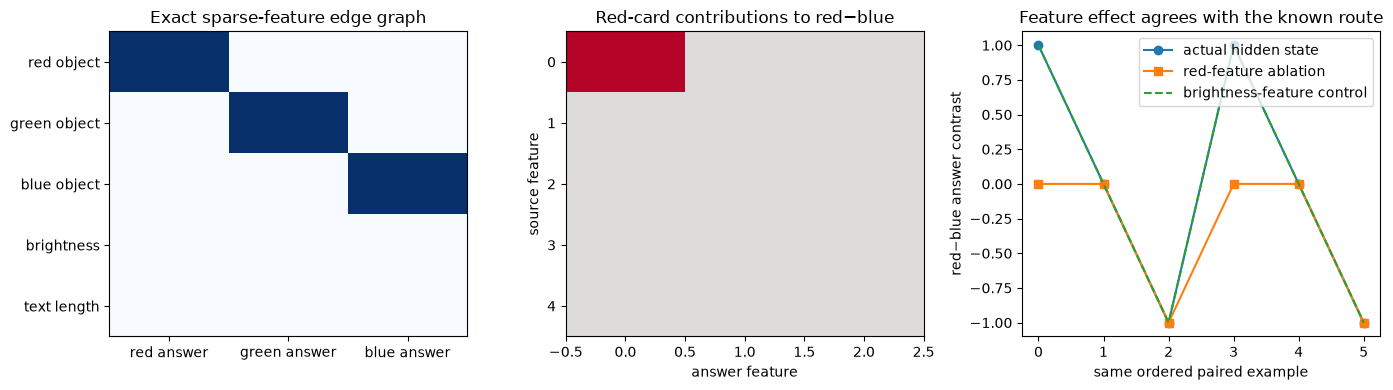

In [ ]:
edges = feature_edges(d_x,mlp_weights)
contrast = np.array([1.,0.,-1.])
contributions = path_contribution(z,edges,contrast)
baseline = transcoder_targets(visual,mlp_weights,mlp_bias) @ contrast
red_ablated = transcoder_targets(latent_ablation(visual,z,d_x,0),mlp_weights,mlp_bias) @ contrast
nuisance_ablated = transcoder_targets(latent_ablation(visual,z,d_x,3),mlp_weights,mlp_bias) @ contrast
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].imshow(edges,aspect="auto",cmap="Blues",vmin=0,vmax=1);axes[0].set(yticks=range(5),yticklabels=feature_names,xticks=range(3),xticklabels=["red answer","green answer","blue answer"],title="Exact sparse-feature edge graph")
axes[1].imshow(contributions[0],aspect="auto",cmap="coolwarm",vmin=-1,vmax=1);axes[1].set(xlabel="answer feature",ylabel="source feature",title="Red-card contributions to red−blue")
axes[2].plot(baseline,"o-",label="actual hidden state");axes[2].plot(red_ablated,"s-",label="red-feature ablation");axes[2].plot(nuisance_ablated,"--",label="brightness-feature control");axes[2].set(xlabel="same ordered paired example",ylabel="red−blue answer contrast",title="Feature effect agrees with the known route");axes[2].legend()
plt.tight_layout();plt.show()

## Interpreting the result

The fixed CPU fixture gives semantic support Jaccard `[1,1,1]` for matched pairs and `[0,0,0]` after the cyclic pairing control. Semantic-only SAE reconstruction error is 0.000685, while the transcoder target error rounds to 0.000000. On the first red card, red-feature ablation changes the red-minus-blue contrast from1 to0; brightness ablation leaves it at1. These are seen teaching-fixture results. The edge panel is the signature sparse circuit: three semantic features reach the matching answer features; the two nuisance features have no route to this readout. Red-feature ablation affects red cards, while removing brightness changes the image representation but not the answer. That difference distinguishes reconstruction relevance from answer relevance. Our exact route permits a ground-truth check unavailable in a released VLM.

To bridge to [12.3], replace our sites by **cached** projector output and LM residuals at separately recorded image/text positions. Keep example/position correspondence, fit on the declared training cohort, select features only on the authorised development data, preserve decoder biases and residual errors, and compare actual activation replacement with the sparse surrogate. A crosscoder between CLIP vision states and VLM image tokens needs a documented resampling/token correspondence; their patch grids need not coincide. No such trained model/cache/circuit is claimed here.

## Try it yourself

Change the answer task so brightness matters. Predict which previously irrelevant feature should acquire an edge, while text length should remain irrelevant. Keep encoders and data fixed. This is a changed computation, not a new random seed.

In [ ]:
play_weights=mlp_weights.copy();play_weights[3,0]=2.0
play_edges=feature_edges(d_x,play_weights)
play_baseline=transcoder_targets(visual,play_weights,mlp_bias) @ contrast
play_removed=transcoder_targets(latent_ablation(visual,z,d_x,3),play_weights,mlp_bias) @ contrast
fig,axes=plt.subplots(1,2,figsize=(10,3.5));axes[0].imshow(play_edges,aspect="auto",cmap="Blues");axes[0].set(xlabel="answer feature",ylabel="source feature",title="Changed task gives brightness a route")
axes[1].plot(play_baseline,"o-",label="brightness-dependent task");axes[1].plot(play_removed,"s--",label="brightness ablated");axes[1].set(xlabel="same example",ylabel="red−blue contrast",title="Predict a formerly absent causal effect");axes[1].legend();plt.tight_layout();plt.show()

## Limitations

The pixel/word features, dictionaries and readout are specified. Fitting a decoder on six monitored pairs does not identify an unsupervised decomposition. Colour, shape and word identity are confounded, and word length correlates with class. The exact linear edge product does not capture nonlinear gating outside this organism. Native VLM SAEs/transcoders/crosscoders, feature discovery, residual/error accounting in real patching, natural images and real sparse circuits remain pending.

# ☆ Bonus

Before changing the recipe, write one prediction about the sign and size of a control difference. After running it, explain a mismatch.

## Further reading

- [Gao et al., Scaling and Evaluating Sparse Autoencoders](https://arxiv.org/abs/2406.04093): compare learned sparse encoders, reconstruction and downstream evaluation to our declared dictionaries.
- [Lindsey et al., Sparse Crosscoders for Cross-Layer Features and Model Diffing](https://transformer-circuits.pub/2024/crosscoders/index.html): read the input/output site distinction and cross-layer shared-feature motivation. The source is a preliminary research update; our two-modality construction is a teaching adaptation.
- [Dunefsky et al., Transcoders Find Interpretable LLM Feature Circuits](https://arxiv.org/abs/2406.11944): compare predicting an MLP output to reconstructing its input, and inspect the limitations of local feature-edge products.
- [Neo et al., Visual Information Processing in VLMs](https://arxiv.org/abs/2410.07149): connect our sites to actual visual-token and language-residual measurements without assuming an exact grid alignment.